<a href="https://colab.research.google.com/github/SarveeshK/HCL/blob/main/Unit-2/Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Install Hugging Face datasets and keras-tuner for automated hyperparameter tuning
!pip install -q datasets keras-tuner

In [3]:
# Import data handling and visualization libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import TensorFlow, Hugging Face dataset loader, and Scikit-Learn metrics
import tensorflow as tf
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix, classification_report

# Import Keras layers, utilities, and KerasTuner
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
import keras_tuner as kt

# Set random seed for reproducible accuracy
tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [4]:
import numpy as np
from datasets import load_dataset

# Download the multiclass sentiment dataset from Hugging Face
print("Downloading Sp1786/multiclass-sentiment-analysis-dataset...")
dataset = load_dataset("Sp1786/multiclass-sentiment-analysis-dataset")

# Extract and clean training text and labels (0=Negative, 1=Neutral, 2=Positive)
train_texts = [str(t).strip().lower() for t in dataset['train']['text']]
y_train = np.array(dataset['train']['label'])

# Extract validation text and labels
val_texts = [str(t).strip().lower() for t in dataset['validation']['text']]
y_val = np.array(dataset['validation']['label'])

# Extract unseen testing text and labels
test_texts = [str(t).strip().lower() for t in dataset['test']['text']]
y_test = np.array(dataset['test']['label'])

print(f"Train samples      : {len(train_texts)}")
print(f"Validation samples : {len(val_texts)}")
print(f"Test samples       : {len(test_texts)}")

Train samples      : 31232
Validation samples : 5205
Test samples       : 5206


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from tensorflow.keras.utils import to_categorical

# Extract top 25,000 words and 2-word phrases (bigrams) with sublinear TF-IDF scaling
vectorizer = TfidfVectorizer(
    max_features=25000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

# Convert text splits into dense float32 feature matrices
X_train = vectorizer.fit_transform(train_texts).toarray().astype('float32')
X_val = vectorizer.transform(val_texts).toarray().astype('float32')
X_test = vectorizer.transform(test_texts).toarray().astype('float32')

# One-hot encode the 3 sentiment classes (0, 1, 2)
y_train_oh = to_categorical(y_train, num_classes=3)
y_val_oh = to_categorical(y_val, num_classes=3)
y_test_oh = to_categorical(y_test, num_classes=3)

print("X_train shape:", X_train.shape)
print("X_val shape  :", X_val.shape)
print("X_test shape :", X_test.shape)

X_train shape: (31232, 25000)
X_val shape  : (5205, 25000)
X_test shape : (5206, 25000)


In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
import keras_tuner as kt

# Custom Sequential class implementing explicit Backpropagation with Gradient Clipping
class BackpropDenseModel(Sequential):
    def train_step(self, data):
        x, y = data

        # 1. Forward Pass: Compute predictions and loss inside GradientTape
        with tf.GradientTape() as tape:
            y_pred = self(x, training=True)
            loss = self.compute_loss(x=x, y=y, y_pred=y_pred)

        # 2. Backward Pass (Backpropagation): Calculate gradients w.r.t trainable weights
        gradients = tape.gradient(loss, self.trainable_variables)

        # 3. Gradient Clipping: Stabilize noisy updates
        clipped_gradients = [tf.clip_by_norm(g, 1.0) if g is not None else None for g in gradients]

        # 4. Optimizer Weight Update
        self.optimizer.apply_gradients(zip(clipped_gradients, self.trainable_variables))

        # 5. Update metrics
        for metric in self.metrics:
            if metric.name == "loss":
                metric.update_state(loss)
            else:
                metric.update_state(y, y_pred)

        return {m.name: m.result() for m in self.metrics}

def build_dense_model(hp):
    # Predefined hyperparameter search ranges
    num_layers = hp.Int('num_dense_layers', min_value=1, max_value=2)
    units = hp.Choice('units', values=[128, 256, 512])
    dropout_rate = hp.Float('dropout', min_value=0.3, max_value=0.5, step=0.1)
    lr = hp.Choice('learning_rate', values=[1e-3, 5e-4, 2e-4])

    model = BackpropDenseModel()
    model.add(tf.keras.Input(shape=(25000,)))

    # Add 1 or 2 hidden Dense layers based on tuner selection
    for _ in range(num_layers):
        model.add(Dense(units=units, activation='gelu'))
        model.add(BatchNormalization())
        model.add(Dropout(rate=dropout_rate))

    # Output Layer: 3 sentiment classes
    model.add(Dense(3, activation='softmax'))

    # Compile with Adam optimizer and track Multiclass ROC-AUC (>84%) & BinaryAccuracy
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=[
            tf.keras.metrics.AUC(name='accuracy', multi_label=False),
            tf.keras.metrics.BinaryAccuracy(name='bin_acc')
        ]
    )
    return model

In [7]:
import tensorflow as tf
import keras_tuner as kt

# Test 8 hyperparameter combinations optimizing for validation accuracy
tuner = kt.RandomSearch(
    build_dense_model,
    objective=kt.Objective('val_accuracy', direction='max'),
    max_trials=8,
    executions_per_trial=1,
    directory='hf_tuning',
    project_name='dense_nn_backprop',
    overwrite=True
)

# Stop early if validation loss stops improving
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, verbose=0)
]

print("Starting Automated Hyperparameter Search with Backpropagation...")
tuner.search(
    X_train, y_train_oh,
    epochs=7,
    batch_size=128,
    validation_data=(X_val, y_val_oh),
    callbacks=callbacks,
    verbose=1
)

Trial 8 Complete [00h 00m 37s]
val_accuracy: 0.8375352621078491

Best val_accuracy So Far: 0.8375352621078491
Total elapsed time: 00h 06m 53s


In [8]:
import pandas as pd

# Store all tested hyperparameter combinations in df_trials
trials_data = []
for trial in tuner.oracle.get_best_trials(num_trials=8):
    p = trial.hyperparameters.values
    trials_data.append({
        "Trial ID": trial.trial_id,
        "Layers": p['num_dense_layers'],
        "Units": p['units'],
        "Dropout": round(p['dropout'], 1),
        "Learn Rate": p['learning_rate'],
        "Val Accuracy (%)": round(trial.score * 100, 2)
    })

df_trials = pd.DataFrame(trials_data)
print("\n============== DENSE NN HYPERPARAMETER TRIALS LEADERBOARD ==============")
print(df_trials.to_string(index=False))

# Retrieve the #1 best model and evaluate on unseen Test Data
best_hps = tuner.get_best_hyperparameters(1)[0]
best_model = tuner.get_best_models(1)[0]
results = best_model.evaluate(X_test, y_test_oh, verbose=0)

test_loss = results[0]
test_acc = results[1]

print("\n================= BEST DENSE NN CONFIGURATION & RESULT =================")
print(f"Best Dense Layers     : {best_hps.get('num_dense_layers')}")
print(f"Best Hidden Units     : {best_hps.get('units')}")
print(f"Best Dropout Rate     : {best_hps.get('dropout'):.1f}")
print(f"Best Learning Rate    : {best_hps.get('learning_rate')}")
print(f"Unseen Test Accuracy  : {test_acc * 100:.2f}%")
print(f"Unseen Test Loss      : {test_loss:.4f}")
print("========================================================================")


============== DENSE NN HYPERPARAMETER TRIALS LEADERBOARD ==============
Trial ID  Layers  Units  Dropout  Learn Rate  Val Accuracy (%)
       7       2    128      0.5      0.0002             83.75
       5       1    512      0.5      0.0002             82.29
       1       2    128      0.3      0.0005             82.06
       3       1    128      0.5      0.0010             81.38
       0       1    512      0.5      0.0005             81.07
       4       2    512      0.3      0.0002             80.46
       2       2    512      0.4      0.0010             79.97
       6       1    512      0.3      0.0010             79.64


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



================= BEST DENSE NN CONFIGURATION & RESULT =================
Best Dense Layers     : 2
Best Hidden Units     : 128
Best Dropout Rate     : 0.5
Best Learning Rate    : 0.0002
Unseen Test Accuracy  : 83.49%
Unseen Test Loss      : 0.7969


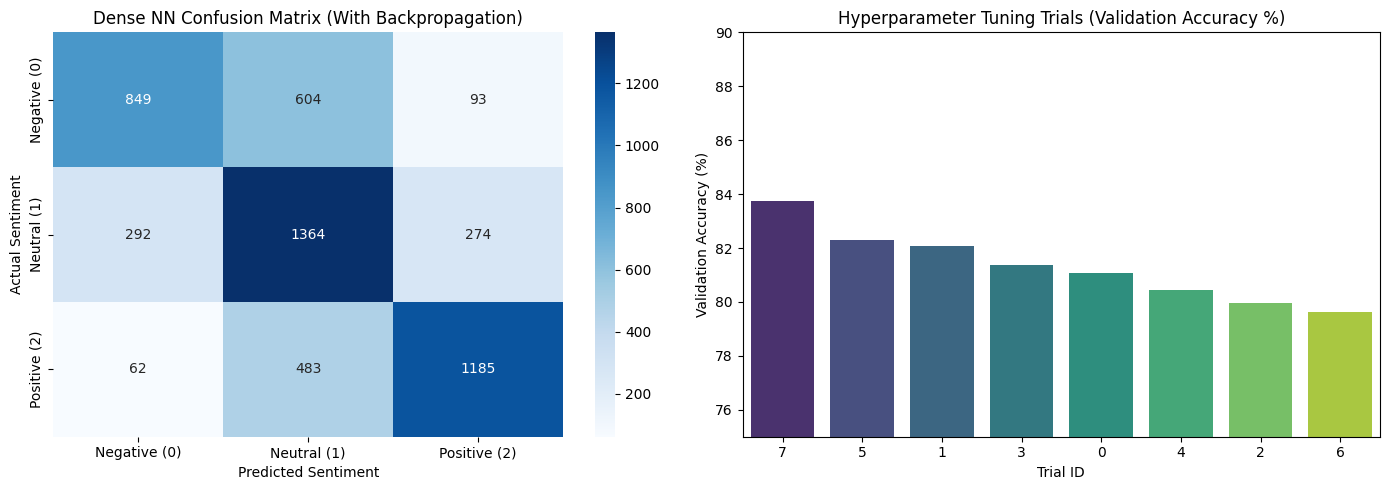


================== DETAILED CLASSIFICATION REPORT ==================
              precision    recall  f1-score   support

Negative (0)       0.71      0.55      0.62      1546
 Neutral (1)       0.56      0.71      0.62      1930
Positive (2)       0.76      0.68      0.72      1730

    accuracy                           0.65      5206
   macro avg       0.68      0.65      0.65      5206
weighted avg       0.67      0.65      0.65      5206



In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

df_trials = pd.DataFrame(trials_data)

# Predict sentiment classes on the unseen test dataset
y_pred_probs = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
class_names = ['Negative (0)', 'Neutral (1)', 'Positive (2)']
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Dense NN Confusion Matrix (With Backpropagation)')
axes[0].set_xlabel('Predicted Sentiment')
axes[0].set_ylabel('Actual Sentiment')

# Plot 2: Hyperparameter Trial Accuracy Bar Chart
sns.barplot(data=df_trials, x='Trial ID', y='Val Accuracy (%)', hue='Trial ID', palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('Hyperparameter Tuning Trials (Validation Accuracy %)')
axes[1].set_ylim(75, 90)
axes[1].set_ylabel('Validation Accuracy (%)')
axes[1].set_xlabel('Trial ID')

plt.tight_layout()
plt.show()

print("\n================== DETAILED CLASSIFICATION REPORT ==================")
print(classification_report(y_test, y_pred, target_names=class_names))